In [1]:
import matplotlib.pylab as plt 
%matplotlib inline
import numpy as np
import rubin_sim.splat as splat
import pandas as pd
import sqlite3
import healpy as hp
import copy
import datetime
import os

from rubin_sim.splat.plots import bright_filter_colors

from rubin_scheduler.utils import (
    angular_separation,
    ddf_locations,hpid2_ra_dec)

from rubin_sim.data import get_baseline
from os.path import basename


In [2]:
db_file = "start_roll_ncs_1_v5.3.7_10yrs.db"
data_source = basename(db_file).replace('.db', '')
con = sqlite3.connect(db_file)
df = pd.read_sql('select * from observations;', con)
con.close()
# Convert to a numpy array
visits_array = df.to_records(index=False)

In [10]:

is_too = np.array(["ToO" in note for note in visits_array["scheduler_note"]])
indx = np.where((visits_array["visitExposureTime"] > 20)  & (~is_too))

info = {"data_source": data_source}
times = np.arange(3653)
metric = splat.AccumulateCountMetric(times)
sl = splat.Slicer(nside=32, missing=0)
hp_time_array, info = sl(visits_array[indx], metric, info=info)

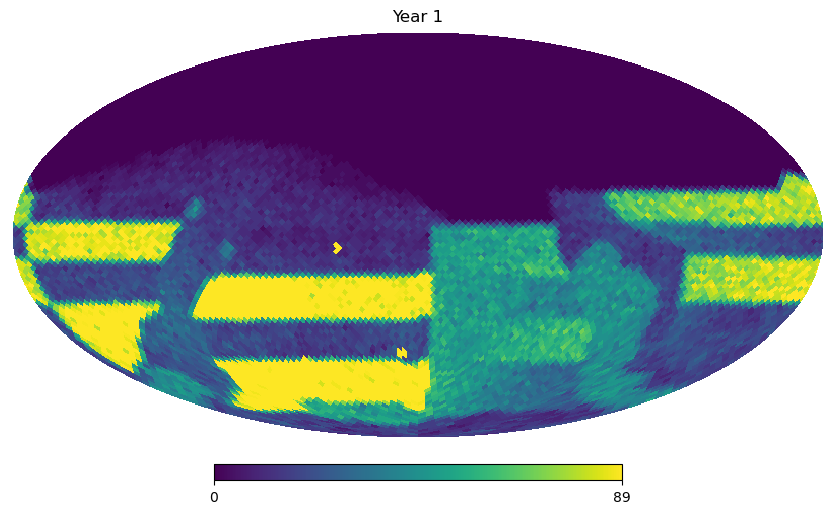

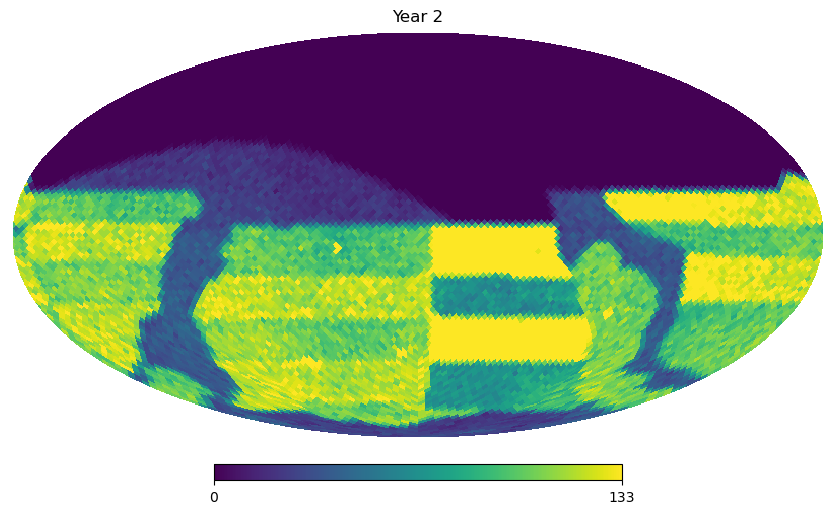

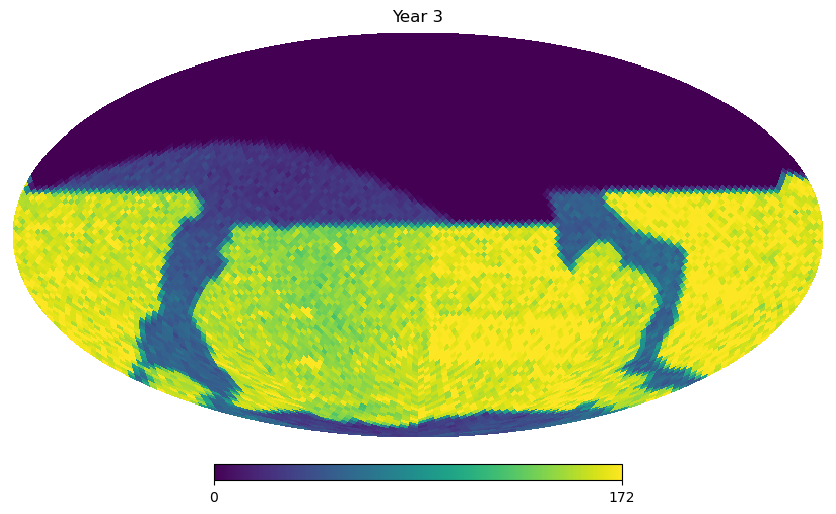

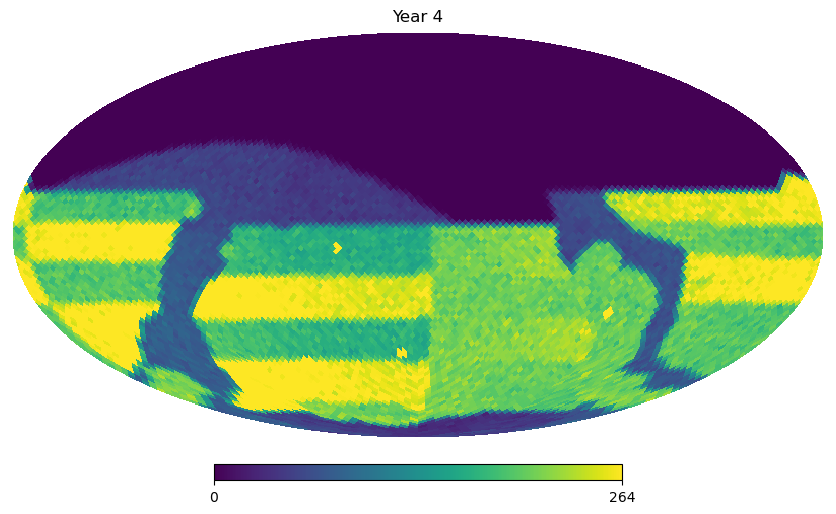

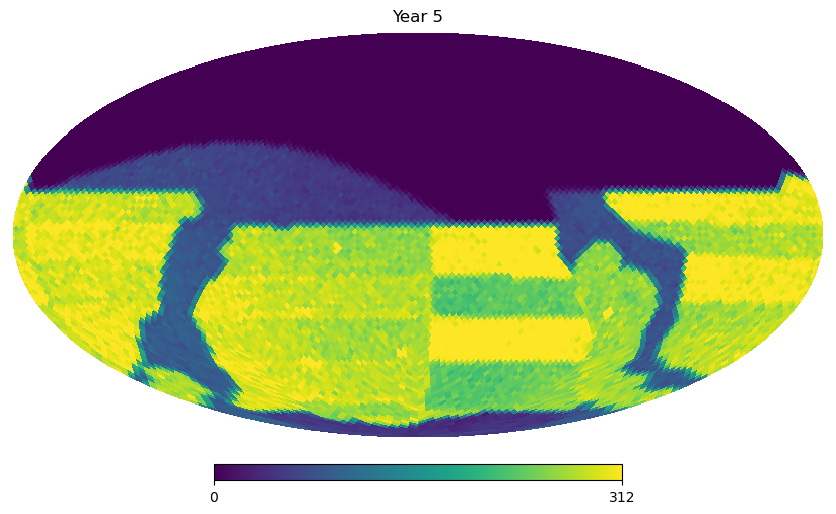

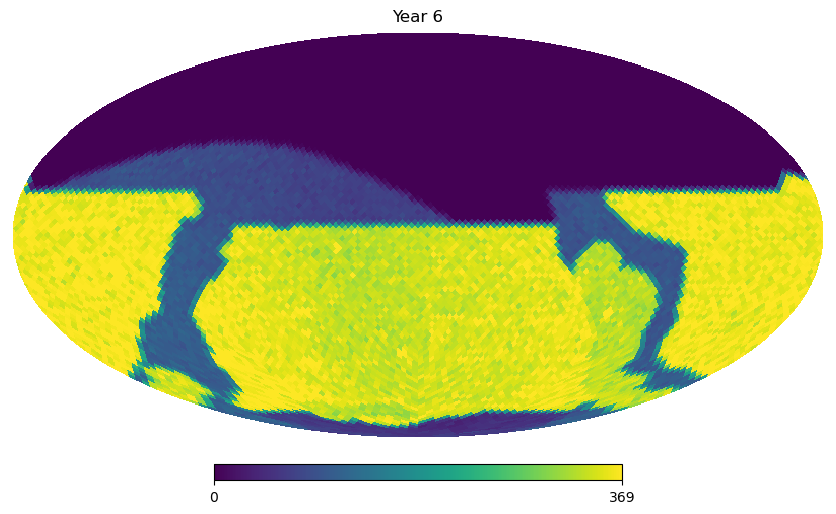

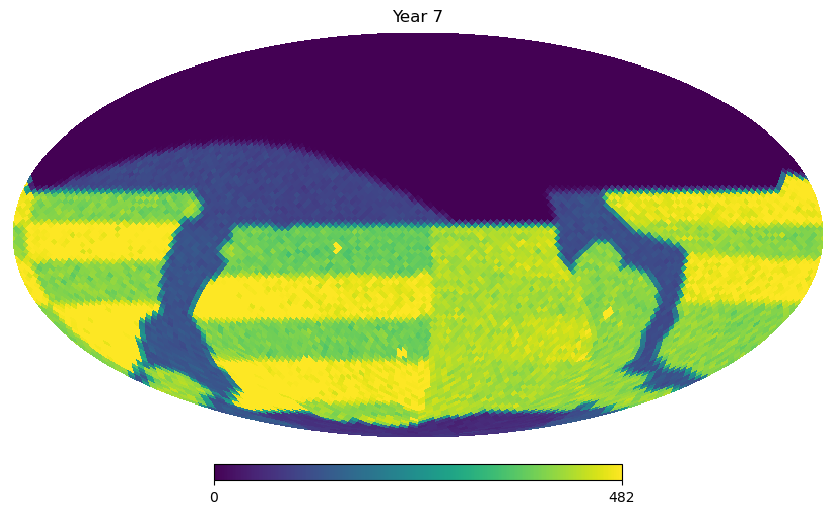

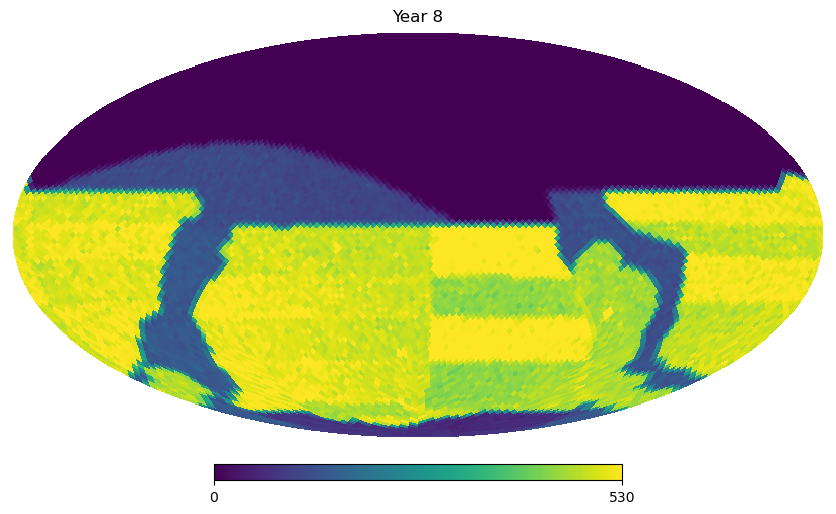

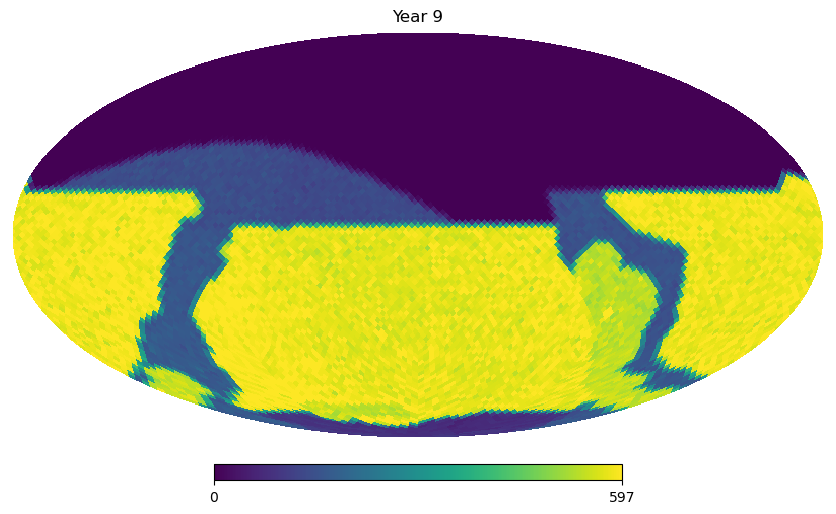

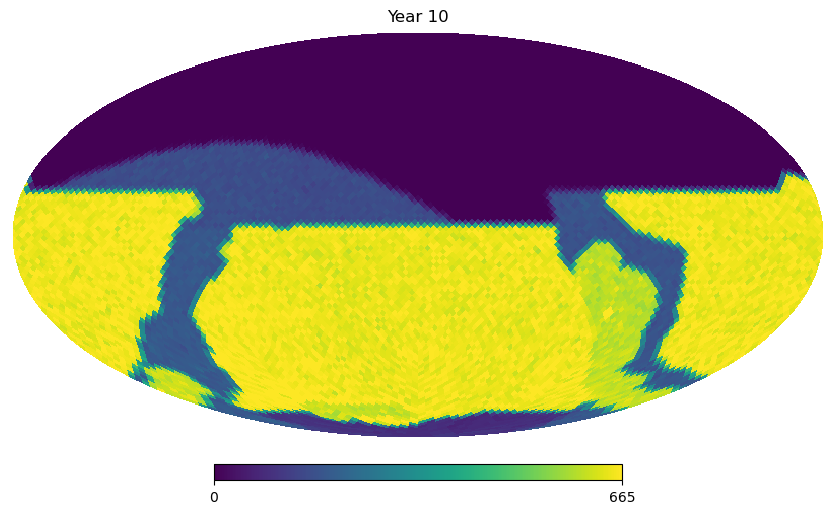

In [13]:
for i in range(10):
    frame = hp_time_array[:,int(365*(i+1))]
    max_val = np.percentile(frame, 92)
    hp.mollview(frame, max=max_val, title="Year %i" % (i+1))